```{contents}
:local:
:depth: 2
```

# 3.3 Global Sampling and Evolutionary Methods

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 7, Lesson 4: *Global Sampling Methods and DIRECT Algorithm*
- Module 7, Lesson 5: *Sampling-Based Stochastic Methods*
- Module 7, Lesson 6: *Sampling-Based Stochastic and Evolutionary Methods*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Contrast global sampling methods with local direct search, and say what "global" does and does not promise.
- State Lipschitz continuity precisely and use a Lipschitz constant to compute a valid lower bound on a black box over an interval.
- Describe how DIRECT divides and samples the search space, and explain why it cannot stop on its own.
- Use a Lipschitz constant to turn DIRECT-style sampling into a method that certifies a gap, and relate it to branch-and-bound.
- Explain the mechanisms of simulated annealing, genetic algorithms and particle swarm optimization, and run scipy's global methods on a black box.
:::

The local methods of {doc}`Topic3.2-Direct-Search_Methods` find the well they start in, and on BB1 this was the global optimum about one time in three. The obvious fix is to stop sampling around one point and to sample the whole box instead, and in this topic we will cover methods designed to do exactly this. Some of these methods are deterministic and systematic, like DIRECT, while others are stochastic and inspired by nature, like simulated annealing, genetic algorithms and particle swarms. None of them, on its own, can know when it has found the global optimum. However, one of them can be made to know if we give it one more number about the function, which is a Lipschitz constant, and this is also the connection between this part and the branch-and-bound of Topics 2.5 and 2.6.

## Global sampling methods

A **global sampling method** collects samples everywhere in the search space, rather than in a small region around a current point. Since there is no current point with a neighborhood to be covered, it does not need positive spanning sets or simplices; instead, it spreads samples over the box and concentrates later samples in the places where earlier ones looked good. The same effect could be achieved, although less systematically, by starting a local method from many points (the multistart of Topic 3.2).

"Global" is a name for the search, not for the result. A global sampling method explores more than a local one, which raises the odds of landing in the best well, but without assumptions about $f$ it has no way to know whether it has. As we saw in Topic 3.1, if we only have samples it is never possible to rule out a narrow well between two samples. Global methods also give up the local guarantee of Topic 3.2, since without derivatives or a controlled pattern it is not possible to prove convergence even to a stationary point, and they usually need many more evaluations, so they are only worth their cost when the landscape has several wells and evaluations are cheap enough. The convergence argument for these methods is about coverage: a good global method keeps its samples from repeating, so if it could sample forever it would eventually sample everywhere and find the global optimum. With a finite budget, how quickly it gets close depends entirely on the heuristics used to decide where to sample next.

This changes the kind of answer we are asking for. A local method returns an **exact local optimum**, which is a point where, under the smoothness assumptions of Topic 3.2, the gradient is zero, but whose value may be poor. A global method returns an **approximate global optimum**, which is a point that may have a much better value but is not exactly stationary, and may be slightly off the bottom of its well. Which of these is preferable depends on the application, and if we polish an approximate global answer with a short local search, as dual annealing does internally, we can get both.

Global sampling methods come in two kinds. **Deterministic** methods, such as DIRECT, give the same samples every time they are run. **Stochastic** methods, such as simulated annealing, genetic algorithms and particle swarm optimization, use random numbers to choose samples, so two runs can give different answers.

It is helpful to have a baseline to judge them all against. Pure random sampling places points uniformly in the box and keeps the best one. On BB1 a sample can only be within $10^{-3}$ of the optimum if it lands very close to an edge, so pure random search is a poor method here, and the next cell measures just how poor it is.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.optimize import direct, differential_evolution, dual_annealing, Bounds
from _lib import electrolyzer as el
from _lib.part3a_tools import Counter

FSTAR1 = 1.58921                      # BB1 optimum (Topic 3.1)
xs = np.linspace(0, 0.9, 900001)
fx = np.array([el.bb1([v]) for v in xs[::100]])
near = np.mean(fx < FSTAR1 + 1e-3)
print(f"fraction of [0, 0.9] where BB1 is within 1e-3 of the optimum: {near:.4f}")
print(f"expected uniform samples until the first such point: about {1 / near:.0f}")

fraction of [0, 0.9] where BB1 is within 1e-3 of the optimum: 0.0004
expected uniform samples until the first such point: about 2250


Only 0.04% of the range is good enough, because $f$ rises steeply away from the edges, so a uniform sampler needs about 2,250 evaluations, on average, to get one sample there, and this is the cost of searching blindly.

:::{exercise}
:label: ex-t33-random

Run pure random search on BB1 with 10 different seeds and a budget of 1,000 evaluations each. In how many runs is the best sample within $10^{-3}$ of 1.58921? Compare with the estimate printed above, and with the success rates of the local methods in Topic 3.2 at the same total budget.
:::

## Lipschitz continuity and lower bounds

A function $f$ is **Lipschitz continuous** on a set $X$ with **Lipschitz constant** $L$ if

$$
|f(x) - f(y)| \le L\, \|x - y\| \quad \text{for all } x, y \in X.
$$

The constant is a bound on how fast $f$ can change, since over a distance $h$, $f$ cannot rise or fall by more than $Lh$. If $f$ is differentiable on an interval, the mean value theorem gives a valid constant directly, $L = \max_{x} |f'(x)|$. For example, $f(x) = x^3$ is Lipschitz on $[1, 2]$, because $|x^3 - y^3| = |x - y|\,|x^2 + xy + y^2| \le 12\,|x - y|$, since $x^2 + xy + y^2 \le 12$ there, and $L = 12$ is also $\max |f'| = 3 \cdot 2^2$. A function can fail to be Lipschitz in two ways. It can jump, like BB3 at its on/off switches and penalty walls, and in this case no $L$ works. Alternatively, it can be continuous but infinitely steep somewhere, and for example $f(x) = \sqrt{x}$ on $[0, 1]$ has $f'(x) = 1/(2\sqrt{x})$, which grows without bound as $x \to 0$, so no single $L$ can bound its slope near zero. At small scale BB1 is close to the second case, since its smoothed fixed charge makes the slope at zero load the largest anywhere, and the smaller $\epsilon$ is, the larger that slope will be.

With Lipschitz continuity, a single sample can be turned into a bound. If $x$ lies within distance $r$ of a sampled point $c$, then $f(x) \ge f(c) - L\,r$, and in particular, over an interval $[a, b]$ sampled at its center $c$,

$$
\min_{x \in [a, b]} f(x) \;\ge\; f(c) - L\,\frac{b - a}{2}.
$$

This is a **valid lower bound** in exactly the sense of Topic 2.6, since no point in the interval can be better than it. With several samples, the bounds from all of them together form a sawtooth of downward cones under $f$, and the lowest point of the sawtooth is a lower bound on the global minimum.

For BB1, we can compute a Lipschitz constant from the formula we have been hiding from the solver, as the largest slope of $f$ over $[0, 0.9]$ on a fine grid, with a 1% safety margin. In a real black-box problem nobody hands us this number, so it has to come from physics (a bound on how fast the power can change with load), from the data, or from experience, and the certificate below is only as good as that number.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


Lipschitz constant of BB1 on [0, 0.9]: L = 5.133 per-unit power per unit load
best sample 1.6425; lower bound from five samples 0.9288; gap 0.7137


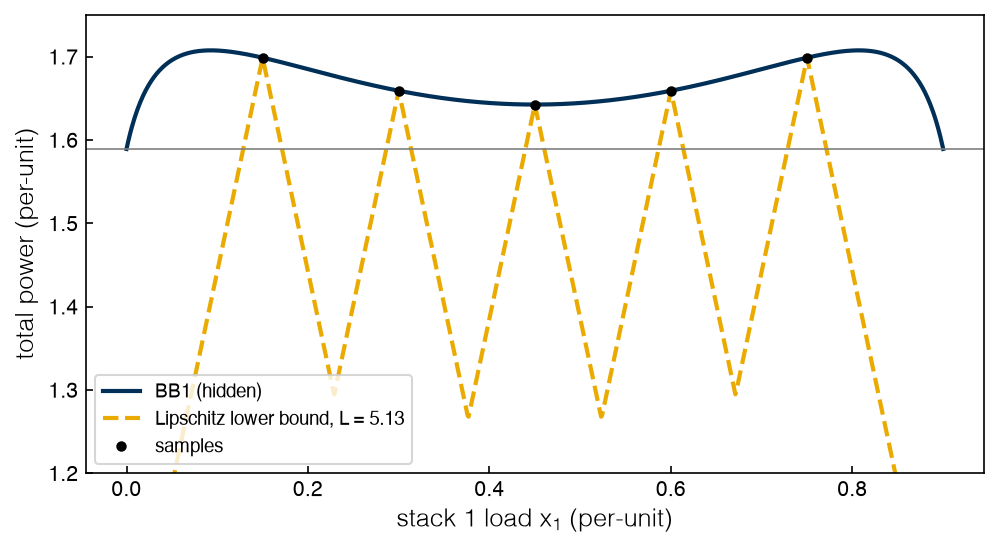

In [2]:
from _lib.part3a_tools import lipschitz_bb1

L = lipschitz_bb1()
print(f"Lipschitz constant of BB1 on [0, 0.9]: L = {L:.3f} per-unit power per unit load")

x = np.linspace(0, 0.9, 901)
f = np.array([el.bb1([v]) for v in x])
samples = np.linspace(0, 0.9, 7)[1:-1]            # five interior samples
fs = np.array([el.bb1([v]) for v in samples])
cones = np.max(fs[:, None] - L * np.abs(x[None, :] - samples[:, None]), axis=0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, f, label='BB1 (hidden)')
ax.plot(x, cones, '--', label=f'Lipschitz lower bound, L = {L:.2f}')
ax.plot(samples, fs, 'ko', ms=4, label='samples')
ax.axhline(FSTAR1, color='0.5', lw=0.8)
ax.set_xlabel('stack 1 load $x_1$ (per-unit)'); ax.set_ylabel('total power (per-unit)')
ax.set_ylim(1.2, 1.75); ax.legend(fontsize=9)
print(f"best sample {fs.min():.4f}; lower bound from five samples {cones.min():.4f}; gap {fs.min() - cones.min():.4f}")

BB1's Lipschitz constant is $L = 5.13$, and the steepest slope is at zero load, because the smoothed fixed charge $a\,x/(x+\epsilon)$ rises fastest just as a stack turns on; this is the same physical feature responsible for the narrow edge wells. With five evenly spaced interior samples, the best sample is the equal split, 1.6425, and the sawtooth bound is 0.9288, which is a gap of 0.71. The bound is weakest near the edges, which are the parts of the box farthest from a sample, and this is exactly where the optimum is hiding. If we want to close the gap, we will need to sample more in the places where the bound is low.

:::{exercise}
:label: ex-t33-lipschitz

(a) Compute a Lipschitz constant for BB1 restricted to $[0.2, 0.7]$ with `lipschitz_bb1(0.2, 0.7)` and explain why it is much smaller than 5.13. (b) Show that BB3 is not Lipschitz continuous by finding two points 0.001 apart whose values differ by more than 1. (c) Redraw the figure with $L = 2$. Is the dashed curve still below $f$ everywhere? What would a method that trusted it conclude?
:::

## The DIRECT algorithm

DIRECT, short for "DIviding RECTangles", was proposed by Jones, Perttunen and Stuckman (1993), motivated by design problems run on car simulations at General Motors, and Jones and Martins (2021) review its first 25 years. It is the most widely used deterministic global sampling method, and the idea behind it is the sawtooth bound above, applied without knowing $L$.

DIRECT normalizes the box to a unit hypercube, samples its center, and then repeats:

1. **Select** the potentially optimal rectangles. A rectangle with center value $f(c)$ and half-diagonal $r$ has the Lipschitz bound $f(c) - Lr$. DIRECT does not know $L$, so it selects every rectangle that would have the lowest bound for *some* value of $L > 0$ (and that could improve on the best value by a meaningful amount). Small $L$ favors rectangles with good center values, which is local refinement; large $L$ favors big rectangles, which is global exploration. Taking all of them at once balances the two without choosing.
2. **Divide** each selected rectangle into thirds along its longest side (a hypercube is divided along every dimension, one after another) and **sample** the centers of the two new outer thirds. The old center stays the center of the middle third, so each division costs two evaluations.

This is "Lipschitzian optimization without the Lipschitz constant". It is also the reason for the weakness of DIRECT, since without ever committing to an $L$ it never has a lower bound, so it cannot prove that it has found the optimum, and it stops only when it runs out of budget or its rectangles become too small. The cell below runs the scipy implementation on BB1 with a budget of 4,000 evaluations and a minimum rectangle size of $10^{-6}$, and it records when the best value found first comes within $10^{-2}$ and $10^{-3}$ of the optimum.

In [3]:
fD = Counter(el.bb1)
r = direct(fD, Bounds([0], [0.9]), maxfun=4000, len_tol=1e-6)
h = np.array(fD.history)
hit2 = np.argmax(h < FSTAR1 + 1e-2) + 1
hit3 = np.argmax(h < FSTAR1 + 1e-3) + 1
print(f"DIRECT on BB1: best {r.fun:.5f} at x1 = {r.x[0]:.4f} after {fD.n} evaluations")
print(f"best within 1e-2 of the optimum at evaluation {hit2}, within 1e-3 at evaluation {hit3}")

DIRECT on BB1: best 1.58921 at x1 = 0.0000 after 2397 evaluations
best within 1e-2 of the optimum at evaluation 55, within 1e-3 at evaluation 81


DIRECT is within $10^{-2}$ of the optimum at evaluation 55 and within $10^{-3}$ at evaluation 81, but then it keeps going for more than 2,300 further evaluations, refining rectangles all over the box, because nothing is telling it that it is done, and it only stops when its rectangles reach the size limit, after 2,397 evaluations. **DIRECT finds, but it cannot prove.**

This pattern, where the method is close to the optimum quickly but is exact only after many more samples, is typical of DIRECT. It is the most popular deterministic global sampling method, with reported uses ranging from power generation, photovoltaic systems and hydrogen fuel cell management to aircraft routing, hard-disk design and genetics. Because its concept is simple and tied directly to Lipschitz theory, DIRECT works well on problems with up to about 10 variables, although with more variables than this the number of rectangles will grow too quickly to be practical.

:::{exercise}
:label: ex-t33-direct

Run `direct` on BB2 over $[0, 1]^2$ with `maxfun=4000` and record, as above, the evaluations at which the best value first comes within $10^{-2}$ and $10^{-3}$ of 2.08181. Then plot the sampled points (wrap `el.bb2` in a function that stores its arguments). Where does DIRECT spend its samples, and why does it take so long to reach the optimum on the edge $x_B = 0$?
:::

## Closing a certified gap on BB1

Now we can give the geometry of DIRECT the one thing it lacks. With a known Lipschitz constant, every interval carries the lower bound $f(c) - L\,(b - a)/2$, and the smallest of these over all the intervals is a lower bound on the global minimum. The best value sampled so far, called the **incumbent**, is an upper bound, and the difference between the two is a **certified gap**, since the incumbent is provably within the gap of the true optimum.

The method in `_lib/part3a_tools.py` (`direct_certified`) runs center-sampled trisection on BB1 (as DIRECT does in one dimension) with two changes. Every interval with a lower bound that could still beat the incumbent is split, while every interval with a lower bound already worse than the incumbent is **discarded**, since the optimum cannot be there, and the method stops when the gap is at most $10^{-3}$. The splitting and discarding rules are exactly the two moves of branch-and-bound in {doc}`../2-nonlinear_mixed_integer/Topic2.5-Branch_and_Bound`, where we branch on the regions that could still hold the optimum and prune the ones proven to be worse. We will run it twice, once with the single global constant $L = 5.13$, and once with a **local** constant for each interval, equal to its own largest slope. The local version uses the formula, so it would not be available to a true black-box method, although it is useful as a way to show how much a tighter constant can buy.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


global L = 5.13       : gap <= 1e-2 after 73 evaluations, gap <= 1e-3 after 83; incumbent 1.58956
local L per interval  : gap <= 1e-2 after 27 evaluations, gap <= 1e-3 after 37; incumbent 1.58956


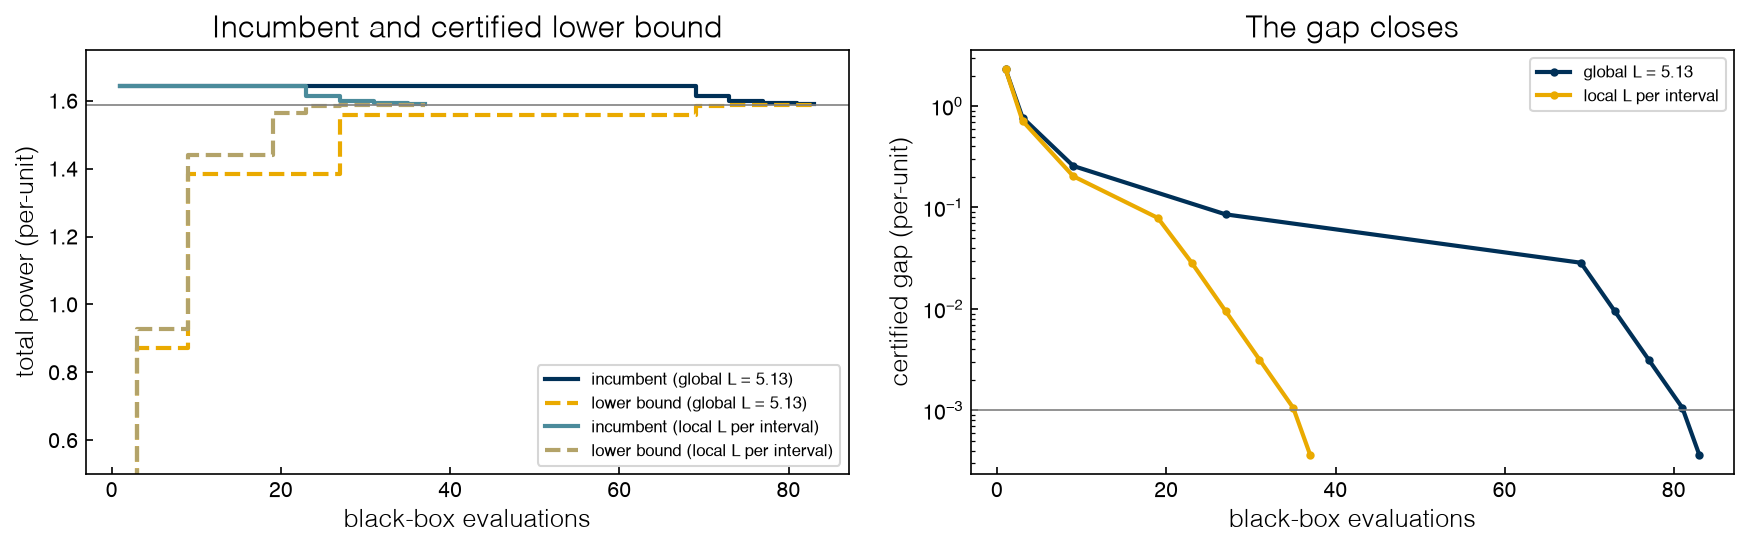

In [4]:
from _lib.part3a_tools import direct_certified

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for local, lab in ((False, 'global L = 5.13'), (True, 'local L per interval')):
    n3, hist = direct_certified(local=local, tol=1e-3)
    H = np.array(hist)
    n2 = int(H[np.argmax(H[:, 1] - H[:, 2] <= 1e-2), 0])
    ax[0].step(H[:, 0], H[:, 1], where='post', label=f'incumbent ({lab})')
    ax[0].step(H[:, 0], np.minimum(H[:, 2], H[:, 1]), where='post', ls='--', label=f'lower bound ({lab})')
    ax[1].semilogy(H[:, 0], H[:, 1] - H[:, 2], 'o-', ms=3, label=lab)
    print(f"{lab:22s}: gap <= 1e-2 after {n2} evaluations, gap <= 1e-3 after {n3}; incumbent {H[-1, 1]:.5f}")
ax[0].axhline(FSTAR1, color='0.5', lw=0.8)
ax[0].set_ylim(0.5, 1.75)
ax[0].set_xlabel('black-box evaluations'); ax[0].set_ylabel('total power (per-unit)'); ax[0].legend(fontsize=8)
ax[0].set_title('Incumbent and certified lower bound')
ax[1].axhline(1e-3, color='0.5', lw=0.8)
ax[1].set_xlabel('black-box evaluations'); ax[1].set_ylabel('certified gap (per-unit)')
ax[1].set_title('The gap closes'); ax[1].legend(fontsize=8)
plt.tight_layout()

With the global constant the gap reaches $10^{-2}$ after 73 evaluations and $10^{-3}$ after 83. The incumbent is 1.58956, which is within the certified $10^{-3}$ of the true optimum 1.58921; center sampling never lands exactly on the edge, so the incumbent is a point very near it. With local constants, the gap is closed after 27 and 37 evaluations. The honest global constant is loose, because the steep slope near zero load is charged to every interval, although it is not so loose as to keep the gap from closing in a readable number of evaluations.

We can now set this result beside Topic 2.6. At the end of {doc}`../2-nonlinear_mixed_integer/Topic2.6-Non-convex_Problems_and_Bounding` we pointed to DIRECT as another route to a certificate, and in this section we have followed that route. In Topic 2.6, spatial branch-and-bound proved the same optimum of the same instance in 12 nodes, with the lower bound of each node coming from a convex relaxation built from the equations. Here the lower bound of each interval comes from one sample and the Lipschitz constant, and the proof requires 83 black-box evaluations. **Branch-and-bound proves with the equations; DIRECT proves with $L$.** The structure of the argument is the same in both cases, with an incumbent above, a valid bound below, branching to tighten the bound, and pruning where the bound already exceeds the incumbent. The difference is the source of the bound, and therefore what we need to trust, since in Topic 2.6 we trusted the relaxation and here we are trusting $L$. If $L$ is too small, the cones poke above $f$, so the "bound" is not a bound, and the method can report a closed gap around the wrong answer, as a local solve passed off as a bound did in Topic 2.6. The moment you trust a bound from a non-convex problem, you are doing global optimization, whether you meant to or not.

:::{exercise}
:label: ex-t33-certificate

Modify a copy of `direct_certified` to use a constant $L$ that you pass in, and run it with $L$ = 10, 5.13, 3 and 1. Report the evaluations to a $10^{-3}$ gap and the incumbent in each case. For which values is the certificate valid? For which does the method stop at the wrong answer, and what does it report about its own gap?
:::

## Stochastic and evolutionary methods

A second family of global sampling methods uses randomness and rules of thumb. These methods are called **stochastic** because random perturbations generate their samples, so the same algorithm run twice with different random seeds can give different results. They are called **heuristic** because their rules are justified by analogy and experience rather than by theorems. They make no assumption about the function, need no derivatives, and can be applied to any problem, including discontinuous ones and problems with integer or binary variables, so they compete directly with direct search for the same problems. In exchange they give no guarantee: their convergence to the global optimum holds only in the limit of infinitely many samples. Heuristics are not unique to these methods, since any rule chosen because it seems to work, such as where to put the initial samples, is a heuristic, while computing a derivative and solving for where it vanishes is not. (They are not methods for optimization *under* uncertainty; that is the subject of the bonus topics on uncertainty, and {doc}`../5-uncertainty/Topic5.1-Stochastic_Programming` separates "stochastic methods" from "stochastic programming".) The lectures present three, each inspired by a natural process.

**Simulated annealing** (Kirkpatrick, Gelatt and Vecchi 1983) imitates the slow cooling of a metal. From the current point it proposes a random nearby point, and a better point is always accepted, while a worse one is accepted with probability $\exp(-\Delta f / T)$, where $\Delta f$ is how much worse it is and $T$ is a "temperature". At the start $T$ is high and the search accepts many uphill moves, so it can climb out of wells, and as $T$ is lowered it settles into the best well it has found, with the cooling schedule and the step size as its tuning parameters.

**Genetic algorithms** (Holland, in the 1960s and 1970s) imitate natural selection and belong to the broader class of **evolutionary algorithms**. We start by evaluating a **population** of candidate points, where each candidate (a vector of decision variables) is called a **chromosome** or individual; classic GAs encode it as a string of bits (genes), while the version below works with real numbers directly. The objective is used as the **fitness** of each individual. Fitter individuals are more likely to be **selected** as parents, pairs of parents are combined by **crossover** into children, some children are randomly **mutated**, and the best individuals may be carried over unchanged (**elitism**). The offspring form the next generation, and the loop ends after a set time or number of generations, or when a good enough solution appears, so that over many generations the population drifts toward good regions. A well-known application of this approach is the evolved antenna NASA used for the 2006 ST5 spacecraft, with an irregular shape found by a genetic algorithm to meet an unusual radiation-pattern requirement. Differential evolution, which can be found in scipy, is a modern relative where children are built from differences between population members.

**Particle swarm optimization** (Kennedy and Eberhart 1995) imitates a flock of birds or a school of fish. Each **particle** has a position and a velocity, and at each step the velocity is pulled toward the best point seen by the particle itself and toward the best point seen by any particle, with random weights, before the particle moves. The swarm explores while the particles disagree and contracts as they converge on a common best point. Many variants of the update formula exist, as well as many other nature-inspired heuristics such as ant colony optimization, and new ones appear regularly.

**Scatter search** (Glover 1977; Laguna and Martí 2003), which is listed in Topic 1.1 with the other stochastic methods, is a population method that works in a more deterministic way. It keeps a small reference set of good and diverse points, combines pairs of them by taking points along and beyond the line between them (rather than by random crossover), and improves the combined points with a local search before deciding which of them enter the reference set. Diversity is managed explicitly through the distance between points, instead of being left to random mutation. We do not implement it here, since its combine-then-improve loop is close to the genetic algorithm above with a local optimizer added.

The next cell implements each method in a few lines on BB1, with a budget of roughly 600 evaluations each. These are teaching versions written to show the mechanism (not production code), and each one is run once with seed 0 and then with 10 seeds to show how much the outcome can vary.

In [5]:
lo, hi = 0.0, 0.9

def sa(f, x0=0.45, T0=0.05, cool=0.97, sigma=0.15, iters=600, seed=0):
    rng = np.random.default_rng(seed); x, fx = x0, f([x0]); best = (fx, x); T = T0
    for _ in range(iters):
        y = float(np.clip(x + sigma * rng.normal(), lo, hi)); fy = f([y])     # random neighbor
        if fy < fx or rng.random() < np.exp(-(fy - fx) / T):                  # Metropolis rule
            x, fx = y, fy
        best = min(best, (fx, x)); T *= cool                                   # cool down
    return best

def ga(f, pop=20, gens=30, pm=0.2, seed=0):
    rng = np.random.default_rng(seed); X = rng.uniform(lo, hi, pop); y = np.array([f([v]) for v in X])
    for _ in range(gens):
        i, j = rng.integers(pop, size=(2, pop))
        parents = np.where(y[i] < y[j], X[i], X[j])                            # tournament selection
        w = rng.random(pop); kids = w * parents + (1 - w) * rng.permutation(parents)   # crossover
        m = rng.random(pop) < pm; kids[m] += 0.1 * rng.normal(size=m.sum())    # mutation
        kids = np.clip(kids, lo, hi); yk = np.array([f([v]) for v in kids])
        kids[0], yk[0] = X[np.argmin(y)], y.min()                              # elitism
        X, y = kids, yk
    return y.min(), X[np.argmin(y)]

def pso(f, n=15, iters=40, w=0.7, c1=1.5, c2=1.5, seed=0):
    rng = np.random.default_rng(seed); X = rng.uniform(lo, hi, n); V = np.zeros(n)
    y = np.array([f([v]) for v in X]); P, py = X.copy(), y.copy()             # personal bests
    for _ in range(iters):
        g = P[np.argmin(py)]                                                   # swarm best
        V = w * V + c1 * rng.random(n) * (P - X) + c2 * rng.random(n) * (g - X)
        X = np.clip(X + V, lo, hi); y = np.array([f([v]) for v in X])
        better = y < py; P[better], py[better] = X[better], y[better]
    return py.min(), P[np.argmin(py)]

for name, method in (('simulated annealing', sa), ('genetic algorithm', ga), ('particle swarm', pso)):
    f = Counter(el.bb1); best, xb = method(f, seed=0)
    wins = sum(method(Counter(el.bb1), seed=s)[0] < FSTAR1 + 1e-3 for s in range(10))
    print(f"{name:20s} seed 0: best {best:.5f} at x1 = {xb:.3f} ({f.n} evaluations); "
          f"optimum found in {wins}/10 seeds")

simulated annealing  seed 0: best 1.58921 at x1 = 0.000 (601 evaluations); optimum found in 10/10 seeds


genetic algorithm    seed 0: best 1.58921 at x1 = 0.000 (620 evaluations); optimum found in 6/10 seeds
particle swarm       seed 0: best 1.58921 at x1 = 0.000 (615 evaluations); optimum found in 9/10 seeds


With seed 0 all three methods find the optimum, at an edge. Over 10 seeds, simulated annealing finds it 10 times, the particle swarm 9 times and the genetic algorithm 6 times, and the misses settle in the equal-split well at 1.6425. There is one detail helping all three on this problem, which is that each clips its samples to the bounds, so any step that would leave the box lands exactly on an edge, and this is where the optimum of BB1 is. A box with its optimum in the interior would not get that help. More generally, these methods can escape wells, but they cost hundreds of evaluations to do it, with an answer that depends on the seed and the tuning.

The lectures weigh the three methods in similar terms. Simulated annealing helps avoid local minima and has many implementations, but the result depends on the cooling schedule, and the returned point is an approximate global optimum that may not even be a local one. Genetic algorithms can use any cost function and are widely used, especially in biomedical and bioengineering work, and they are likely to find the region of the global minimum, but good settings are hard to find, the process is slow and may not converge, and exact solutions are rare. Implementations of particle swarms are easy to find, and they can locate the region of the global optimum, but they need many samples, and because the swarm crowds around the best region, it is costly to pin down the exact optimum. All three come with no guarantee of local or global optimality, and a rerun from a different seed can give a different answer, although with infinitely many samples they would all converge to the same solution.

These methods are a good choice when an approximate global solution is good enough, the problem has discontinuities or noise, and evaluations are cheap. They should be avoided when evaluations are expensive, since they need many of them, and when the equations exist, since a derivative-based or global deterministic solver can then do better and prove it.

:::{exercise}
:label: ex-t33-heuristics

Change one tuning parameter of each method and rerun the 10-seed count: the cooling rate `cool` of simulated annealing (try 0.9 and 0.995), the mutation probability `pm` of the genetic algorithm (try 0 and 0.5), and the inertia `w` of the swarm (try 0.3 and 0.95). Which changes help, which hurt, and why? Then replace `np.clip` in `sa` with a rule that rejects out-of-bounds proposals, and report the effect.
:::

## Global methods on BB1 and BB2

For real runs we will use library implementations. In scipy there is DIRECT (`direct`), a generalized simulated annealing (`dual_annealing`, which also runs a local search from promising points) and differential evolution (`differential_evolution`), but no particle swarm. The cell below repeats the experiment of Topic 3.2 with these methods, using 30 seeds for the stochastic ones, one run for the deterministic DIRECT, a definition of success as a result within $10^{-3}$ of the optimum, and a budget of about 4,000 evaluations.

In [6]:
def global_table(name, bb, lo, hi, fstar, seeds=30, tol=1e-3):
    lo, hi = np.array(lo, float), np.array(hi, float); bounds = list(zip(lo, hi))
    for meth in ('DIRECT', 'diff. evolution', 'dual annealing'):
        hits, nf, vals = 0, [], []
        for k in range(1 if meth == 'DIRECT' else seeds):
            f = Counter(bb)
            if meth == 'DIRECT':
                fx = direct(f, Bounds(lo, hi), maxfun=4000, len_tol=1e-6).fun
                first = np.argmax(np.array(f.history) < fstar + tol) + 1
                print(f"{name}  DIRECT first within {tol} of the optimum at evaluation {first}")
            elif meth == 'diff. evolution':
                fx = differential_evolution(f, bounds, seed=k, tol=1e-8, polish=False).fun
            else:
                fx = dual_annealing(f, bounds, seed=k, maxfun=4000).fun
            hits += abs(fx - fstar) < tol; nf.append(f.n); vals.append(fx)
        runs = 1 if meth == 'DIRECT' else seeds
        print(f"{name}  {meth:16s} success {hits:2d}/{runs:<2d}  median evaluations {int(np.median(nf)):5d}  "
              f"worst result {max(vals):.5f}")

global_table('BB1', el.bb1, [0], [0.9], 1.58921)
global_table('BB2', el.bb2, [0, 0], [1, 1], 2.08181)

BB1  DIRECT first within 0.001 of the optimum at evaluation 81
BB1  DIRECT           success  1/1   median evaluations  2397  worst result 1.58921


BB1  diff. evolution  success 15/30  median evaluations   367  worst result 1.64250

BB1  dual annealing   success 30/30  median evaluations  2013  worst result 1.58921
BB2  DIRECT first within 0.001 of the optimum at evaluation 835
BB2  DIRECT           success  1/1   median evaluations  4003  worst result 2.08199


BB2  diff. evolution  success 10/30  median evaluations  1695  worst result 2.14236


BB2  dual annealing   success 22/30  median evaluations  4000  worst result 2.09012


| Black box | Method | Success | Median evaluations | Worst result |
|---|---|---|---|---|
| BB1 | DIRECT | 1/1 | 2,397 | 1.58921 |
| | differential evolution | 15/30 | 367 | 1.64250 |
| | dual annealing | 30/30 | 2,013 | 1.58921 |
| BB2 | DIRECT | 1/1 | 4,003 | 2.08199 |
| | differential evolution | 10/30 | 1,695 | 2.14236 |
| | dual annealing | 22/30 | 4,000 | 2.09012 |

We can compare this with Topic 3.2, where Nelder–Mead and compass search succeeded 9 and 8 times in 30 on BB1, and 4 and 3 times on BB2. Dual annealing is the most reliable method here, at the price of using its whole budget, while differential evolution is cheaper and succeeds about half the time on BB1 and a third of the time on BB2, with its failures in the equal-split well on BB1 and in other wells on BB2. DIRECT is successful on both, deterministically, but runs to its budget because it cannot stop on its own; on BB2 it first came within $10^{-3}$ of the optimum after 835 evaluations, which is much later than on BB1, because the optimum lies on the edge $x_B = 0$, and center sampling can only approach this edge slowly.

None of these methods certifies its answer. Each of the 30 dual-annealing runs on BB1 found the optimum, but nothing in the run says so, and we only know because the answer was proven in Topic 2.6. On a black box without a Lipschitz constant, "30 out of 30" is the strongest statement we can make, and it is a statement about our experiment, not about the problem.

The same methods on BB3, the full MINLP as a black box, behave differently again, and the reasons have to do with how the constraints are formulated, which is the subject of {doc}`Topic3.4-Constraints_in_Data-Driven_Optimization`.

:::{exercise}
:label: ex-t33-budget

Rerun `global_table` for BB1 with dual annealing limited to `maxfun=500` and then `maxfun=1000`, and with differential evolution at `popsize=5` and `popsize=30`. Plot success rate against median evaluations for every configuration, together with the multistart compass search of Topic 3.2 (8/30 at 47 evaluations per run, so about 1,400 in total). Which method would you choose if each evaluation took one minute?
:::

## Summary

- Global sampling methods sample the whole box. "Global" describes the search, not a guarantee; without assumptions on $f$, no sampling method can prove its answer.
- A function is Lipschitz continuous with constant $L$ if $|f(x) - f(y)| \le L\|x - y\|$; then one center sample gives the valid bound $f(c) - L\,(b-a)/2$ over an interval. BB1 has $L = 5.13$, set by the steep slope at zero load. BB3, with jumps, has none.
- DIRECT divides rectangles and samples their centers, selecting every rectangle that could be best for some $L$. On BB1 it is within $10^{-3}$ of the optimum at evaluation 81 but runs to 2,397, because it cannot stop on its own.
- With the Lipschitz constant, the same trisection closes a certified gap: $10^{-3}$ after 83 evaluations with the global $L$, 37 with local constants. Branch-and-bound proved the same optimum in 12 nodes with the equations; DIRECT proves it with $L$.
- Simulated annealing, genetic algorithms and particle swarms are heuristic, seed-dependent global methods. With scipy's versions on BB1, dual annealing succeeds 30/30 and differential evolution 15/30; on BB2, 22/30 and 10/30.

## Additional Reading

- Jones, D. R., Perttunen, C. D., and Stuckman, B. E. (1993). Lipschitzian optimization without the Lipschitz constant. *Journal of Optimization Theory and Applications*, 79, 157–181.
- Jones, D. R., and Martins, J. R. R. A. (2021). The DIRECT algorithm: 25 years later. *Journal of Global Optimization*, 79, 521–566.
- Kirkpatrick, S., Gelatt, C. D., Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
- Kennedy, J., and Eberhart, R. (1995). Particle swarm optimization. *Proceedings of the IEEE International Conference on Neural Networks*, IV, 1942–1948.
- Laguna, M., and Martí, R. (2003). *Scatter Search: Methodology and Implementations in C*. Springer.
- Storn, R., and Price, K. (1997). Differential evolution: a simple and efficient heuristic for global optimization over continuous spaces. *Journal of Global Optimization*, 11, 341–359.
- Rios, L. M., and Sahinidis, N. V. (2013). Derivative-free optimization: a review of algorithms and comparison of software implementations. *Journal of Global Optimization*, 56, 1247–1293.